# 신뢰도분석과 상관분석 레포트
## 설문 문항의 내적 일관성 검증과 요인점수 간 관계 분석

본 레포트는 설문조사 데이터를 대상으로 두 단계의 분석을 수행한다.

1. **신뢰도분석(Reliability Analysis)**: 하나의 요인(개념)을 측정하기 위해 여러 문항을
   함께 사용했을 때, 그 문항들이 서로 일관되게 응답되었는지를 Cronbach's alpha로 검증한다.
   신뢰도가 낮은 척도는 같은 개념을 측정한다고 보기 어렵기 때문에, 이후 요인분석이나
   요인점수를 활용한 분석의 전제 조건이 된다.
2. **상관분석(Correlation Analysis)**: 신뢰도가 확인된 문항들을 바탕으로 산출된 요인점수
   (요인분석 결과물)들 사이에 어떤 상관관계가 있는지 Pearson 상관계수로 확인한다.

즉 본 레포트는 "문항 → (신뢰도 검증) → 요인 → (상관관계 검증) → 요인 간 관계"로 이어지는
전형적인 설문 기반 분석의 중간 단계를 다룬다.

### 분석 절차 개요
1. 데이터셋 소개
2. 환경 설정 및 데이터 불러오기
3. 신뢰도분석(Cronbach's alpha)
   - 요인별 문항 구성 정의
   - 요인별 Cronbach's alpha 산출
   - 문항 제거 시 Cronbach's alpha 변화 확인
   - 수정된 문항-전체 상관(corrected item-total correlation) 확인
   - 신뢰도 시각화 및 해석
4. 상관분석(Pearson correlation)
   - 요인점수 데이터 불러오기 및 탐색
   - 요인점수 간 Pearson 상관계수 및 유의확률 산출
   - 상관행렬 시각화(히트맵, 산점도 행렬)
   - 상관관계 해석
5. 종합 결론

## 1. 데이터셋 소개

본 분석에는 두 개의 데이터 파일을 사용한다. 두 파일은 같은 설문조사의 같은 응답자
325명을 서로 다른 단계에서 바라본 것이다.

### 1.1 `fac_analys.csv` (원본 문항 데이터)

- 응답자 325명이 15개의 설문 문항(no1~no15)에 1~5점 리커트 척도로 응답한 원자료이다.
- 15개 문항은 사전에 설계 단계에서 5개의 개념(요인)을 측정하도록 3개씩 묶여 있다.

| 요인 | 문항 | 의미(가정) |
|---|---|---|
| 외관 | no1, no2, no3 | 매장/서비스의 외관에 대한 만족도 |
| 유용성 | no4, no5, no6 | 서비스 이용의 유용성에 대한 인식 |
| 편의성 | no7, no8, no9 | 접근 및 이용 편의성에 대한 인식 |
| 구매의도 | no10, no11, no12 | 향후 구매/재이용 의도 |
| 구전의도 | no13, no14, no15 | 타인에게 추천하거나 긍정적으로 언급할 의도 |

신뢰도분석은 이 원본 문항 데이터를 대상으로, "같은 요인으로 묶인 3개 문항이 실제로
일관되게 응답되었는가"를 검증하기 위해 사용한다.

### 1.2 `factor_scores.csv` (요인점수 데이터)

- 위 15개 문항에 대해 요인분석(탐색적 요인분석)을 실시하여 산출한 응답자별 요인점수이다.
- 하나의 요인에 속한 3개 문항의 정보를 하나의 점수로 압축한 것으로, 개별 문항 대신
  요인 단위로 응답자를 비교하거나 요인 간 관계를 살펴볼 때 사용한다.
- 컬럼: `fs외관`, `fs유용성`, `fs편의성`, `fs구매의도`, `fs구전의도` (총 5개 요인점수)
- 요인점수는 표준화된 값이므로 평균이 0에 가깝고, 양수는 해당 요인에 대한 인식이
  평균보다 높음을, 음수는 평균보다 낮음을 의미한다.

상관분석은 이 요인점수 데이터를 대상으로, "요인들 사이에 어떤 관계가 있는가"(예: 외관에
대한 만족도가 높은 사람이 구매의도도 높은 경향이 있는가)를 검증하기 위해 사용한다.

### 1.3 두 데이터의 관계

`factor_scores.csv`는 `fac_analys.csv`의 15개 문항을 요인분석으로 압축한 결과물이다.
따라서 신뢰도분석(문항 단계)이 먼저 선행되어 "각 요인을 구성하는 문항들이 믿을 만하다"는
것이 확인되어야, 그 문항들로부터 산출된 요인점수를 이용한 후속 분석(상관분석, 회귀분석
등)도 의미를 가진다. 본 레포트가 신뢰도분석을 먼저, 상관분석을 그다음에 배치한 이유가
여기에 있다.

## 2. 환경 설정 및 데이터 불러오기

In [1]:
# (처음 실행 시, 아래 주석을 해제하여 필요한 패키지를 설치하세요)
# !pip install pandas numpy scipy matplotlib seaborn pingouin

# 데이터 분석
import numpy as np
import pandas as pd
from pathlib import Path

# 통계 분석
from pingouin import cronbach_alpha
from scipy.stats import pearsonr

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 출력 설정 (Windows 기준 맑은고딕 폰트 사용)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

### 데이터 경로 설정

노트북이 `data-analysis-practice/practice/` 폴더에 있고, 분석에 사용할 두 CSV 파일은
한 단계 상위 폴더인 `data-analysis-practice/source/` 폴더에 있으므로, 현재 노트북 위치를
기준으로 상위 폴더의 `source` 폴더를 가리키도록 경로를 설정한다.

In [2]:
BASE_DIR = Path.cwd()                      # 현재 노트북(practice 폴더) 위치
SOURCE_DIR = BASE_DIR.parent / 'source'    # data-analysis-practice/source 폴더

print('노트북 위치   :', BASE_DIR)
print('데이터 폴더   :', SOURCE_DIR)
print('fac_analys.csv 존재 여부    :', (SOURCE_DIR / 'fac_analys.csv').exists())
print('factor_scores.csv 존재 여부 :', (SOURCE_DIR / 'factor_scores.csv').exists())

노트북 위치   : c:\Users\황태하\data-analysis-practice\practice
데이터 폴더   : c:\Users\황태하\data-analysis-practice\source
fac_analys.csv 존재 여부    : True
factor_scores.csv 존재 여부 : True


In [3]:
raw_data = pd.read_csv(SOURCE_DIR / 'fac_analys.csv')

print('원본 문항 데이터 크기(행, 열):', raw_data.shape)
raw_data.head()

원본 문항 데이터 크기(행, 열): (325, 16)


,No,no1,no2,no3,no4,no5,no6,no7,no8,no9,no10,no11,no12,no13,no14,no15
0,1,4,4,4,4,4,4,3,3,3,3,2,3,3,3,3
1,2,5,5,5,5,3,3,3,3,3,1,1,1,5,5,5
2,3,5,5,4,4,4,4,3,3,3,3,3,3,5,3,4
3,4,5,5,5,4,4,4,4,4,4,1,1,1,3,3,3
4,5,5,5,5,4,4,4,3,3,3,3,3,3,5,5,5


In [4]:
# 식별자(No) 컬럼을 제외하고, 15개 문항만 남긴다.
df = raw_data.iloc[:, 1:]

print('결측치 개수:', df.isna().sum().sum())
df.describe().T

결측치 개수: 0


,count,mean,std,min,25%,50%,75%,max
no1,325.0,3.686154,1.170612,1.0,3.0,4.0,5.0,5.0
no2,325.0,3.560000,1.194225,1.0,3.0,3.0,5.0,5.0
no3,325.0,3.544615,1.089517,1.0,3.0,4.0,4.0,5.0
no4,325.0,4.024615,0.602984,2.0,4.0,4.0,4.0,5.0
no5,325.0,3.821538,0.617765,2.0,3.0,4.0,4.0,5.0
no6,325.0,3.843077,0.691654,2.0,3.0,4.0,4.0,5.0
no7,325.0,3.252308,0.752179,1.0,3.0,3.0,4.0,5.0
no8,325.0,3.116923,0.815659,1.0,3.0,3.0,3.0,5.0
no9,325.0,3.156923,0.759705,1.0,3.0,3.0,3.0,5.0
no10,325.0,2.775385,0.982255,1.0,2.0,3.0,3.0,5.0


## 3. 신뢰도분석 (Cronbach's alpha)

### 3.1 요인별 문항 구성 정의

1.1절에서 설명한 대로, 15개 문항을 5개 요인으로 그룹화한다. 이 그룹화는 설문을 설계할
때부터 정해진 것으로, 요인분석에서 산출되는 요인 구조와도 일치해야 한다(일치하지 않는다면
설계 단계의 개념 구분 자체를 재검토해야 한다).

In [5]:
factor_groups = {
    '외관': ['no1', 'no2', 'no3'],
    '유용성': ['no4', 'no5', 'no6'],
    '편의성': ['no7', 'no8', 'no9'],
    '구매의도': ['no10', 'no11', 'no12'],
    '구전의도': ['no13', 'no14', 'no15'],
}

for name, cols in factor_groups.items():
    print(f'{name}: {cols}')

외관: ['no1', 'no2', 'no3']
유용성: ['no4', 'no5', 'no6']
편의성: ['no7', 'no8', 'no9']
구매의도: ['no10', 'no11', 'no12']
구전의도: ['no13', 'no14', 'no15']


### 3.2 요인별 Cronbach's alpha 산출

Cronbach's alpha는 0~1 사이의 값을 가지며, 일반적으로 다음과 같은 기준으로 해석한다.

| alpha 값 | 해석 |
|---|---|
| 0.9 이상 | 매우 높음(문항 간 중복 가능성도 검토) |
| 0.8 ~ 0.9 | 높음 |
| 0.7 ~ 0.8 | 양호(일반적인 수용 기준) |
| 0.6 ~ 0.7 | 다소 낮음(탐색적 연구에서는 허용 가능) |
| 0.6 미만 | 신뢰할 수 없음 |

`pingouin.cronbach_alpha`는 alpha 값과 함께 95% 신뢰구간을 반환한다.

In [6]:
alpha_results = []
for factor_name, cols in factor_groups.items():
    factor_df = df[cols]
    alpha_value, ci = cronbach_alpha(factor_df)
    alpha_results.append({
        'Factor': factor_name,
        '문항 수': len(cols),
        "Cronbach's alpha": alpha_value,
        '95% CI 하한': ci[0],
        '95% CI 상한': ci[1],
    })

alpha_df = pd.DataFrame(alpha_results)
alpha_df.round(3)

,Factor,문항 수,Cronbach's alpha,95% CI 하한,95% CI 상한
0,외관,3,0.953,0.943,0.961
1,유용성,3,0.758,0.709,0.800
2,편의성,3,0.869,0.842,0.892
3,구매의도,3,0.883,0.859,0.903
4,구전의도,3,0.814,0.776,0.847


### 3.3 문항 제거 시 Cronbach's alpha 변화 ("항목 제거 시 alpha")

각 요인에서 문항을 하나씩 제외했을 때 alpha 값이 어떻게 변하는지 확인한다. 특정 문항을
제거했을 때 alpha가 오히려 더 높아진다면, 그 문항이 다른 문항들과 잘 어울리지 않는다는
신호이므로 척도에서 제외하거나 문항 표현을 재검토할 후보가 된다.

In [7]:
item_removed_rows = []
for factor_name, cols in factor_groups.items():
    base_alpha, _ = cronbach_alpha(df[cols])
    for col in cols:
        reduced_cols = [c for c in cols if c != col]
        reduced_alpha, _ = cronbach_alpha(df[reduced_cols])
        item_removed_rows.append({
            'Factor': factor_name,
            '제거한 문항': col,
            '원래 alpha': base_alpha,
            '제거 후 alpha': reduced_alpha,
            '변화': reduced_alpha - base_alpha,
        })

item_removed_df = pd.DataFrame(item_removed_rows)
item_removed_df.round(4)

,Factor,제거한 문항,원래 alpha,제거 후 alpha,변화
0,외관,no1,0.9528,0.9433,-0.0095
1,외관,no2,0.9528,0.9209,-0.0319
2,외관,no3,0.9528,0.9279,-0.0248
3,유용성,no4,0.7582,0.6808,-0.0774
4,유용성,no5,0.7582,0.6799,-0.0782
5,유용성,no6,0.7582,0.6671,-0.0910
6,편의성,no7,0.8691,0.7995,-0.0697
7,편의성,no8,0.8691,0.7988,-0.0703
8,편의성,no9,0.8691,0.8467,-0.0225
9,구매의도,no10,0.8829,0.8279,-0.0549


'변화' 열이 양수인 행은, 해당 문항을 제거했을 때 alpha가 오히려 상승한다는 뜻이다.
아래에서 변화가 양수인 문항이 있는지 자동으로 확인한다.

In [8]:
worsening_items = item_removed_df[item_removed_df['변화'] > 0]

if len(worsening_items) == 0:
    print('문항을 제거했을 때 alpha가 상승하는 경우는 없다.')
    print('즉, 현재 요인을 구성하는 모든 문항이 신뢰도에 긍정적으로 기여하고 있다.')
else:
    print('아래 문항들은 제거 시 오히려 alpha가 상승하므로, 재검토가 필요하다.')
    print(worsening_items.round(4))

문항을 제거했을 때 alpha가 상승하는 경우는 없다.
즉, 현재 요인을 구성하는 모든 문항이 신뢰도에 긍정적으로 기여하고 있다.


### 3.4 수정된 문항-전체 상관 (Corrected Item-Total Correlation)

문항 제거 시 alpha 변화와 함께 자주 함께 보는 지표로, 각 문항이 같은 요인에 속한 "나머지
문항들의 합"과 얼마나 강하게 상관되어 있는지를 나타낸다. 이 값이 낮으면(일반적으로 0.3
미만) 그 문항이 같은 개념을 측정하고 있지 않을 가능성이 있다.

In [9]:
item_total_rows = []
for factor_name, cols in factor_groups.items():
    for col in cols:
        other_cols = [c for c in cols if c != col]
        total_of_others = df[other_cols].sum(axis=1)
        r, p = pearsonr(df[col], total_of_others)
        item_total_rows.append({
            'Factor': factor_name,
            '문항': col,
            '수정된 문항-전체 상관': r,
        })

item_total_df = pd.DataFrame(item_total_rows)
item_total_df.round(3)

,Factor,문항,수정된 문항-전체 상관
0,외관,no1,0.884
1,외관,no2,0.914
2,외관,no3,0.907
3,유용성,no4,0.586
4,유용성,no5,0.585
5,유용성,no6,0.600
6,편의성,no7,0.769
7,편의성,no8,0.769
8,편의성,no9,0.715
9,구매의도,no10,0.781


### 3.5 신뢰도 시각화

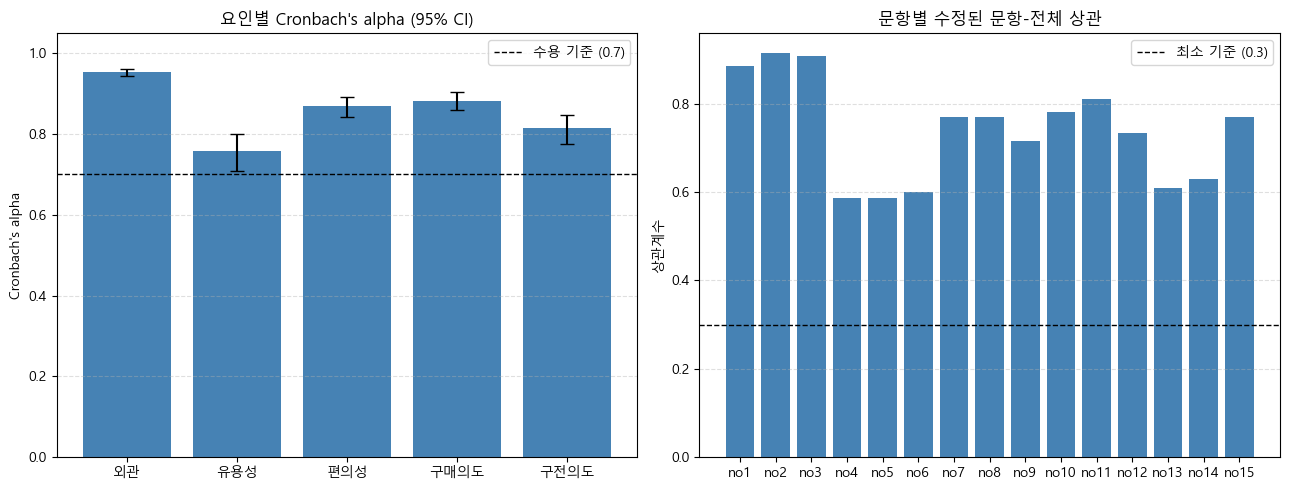

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (좌) 요인별 Cronbach's alpha 막대그래프 + 신뢰구간 에러바
ax = axes[0]
colors = ['steelblue' if a >= 0.7 else 'indianred' for a in alpha_df["Cronbach's alpha"]]
y_err = [
    alpha_df["Cronbach's alpha"] - alpha_df['95% CI 하한'],
    alpha_df['95% CI 상한'] - alpha_df["Cronbach's alpha"],
]
ax.bar(alpha_df['Factor'], alpha_df["Cronbach's alpha"], color=colors,
       yerr=y_err, capsize=5)
ax.axhline(y=0.7, color='black', linestyle='--', linewidth=1, label='수용 기준 (0.7)')
ax.set_ylim(0, 1.05)
ax.set_title("요인별 Cronbach's alpha (95% CI)")
ax.set_ylabel("Cronbach's alpha")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)

# (우) 문항별 수정된 문항-전체 상관
ax2 = axes[1]
item_labels = item_total_df['Factor'] + '\n' + item_total_df['문항']
bar_colors = ['steelblue' if r >= 0.3 else 'indianred' for r in item_total_df['수정된 문항-전체 상관']]
ax2.bar(range(len(item_total_df)), item_total_df['수정된 문항-전체 상관'], color=bar_colors)
ax2.axhline(y=0.3, color='black', linestyle='--', linewidth=1, label='최소 기준 (0.3)')
ax2.set_xticks(range(len(item_total_df)))
ax2.set_xticklabels(item_total_df['문항'], rotation=0)
ax2.set_title('문항별 수정된 문항-전체 상관')
ax2.set_ylabel('상관계수')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### 3.6 신뢰도분석 결과 해석

- 5개 요인 모두 Cronbach's alpha가 0.7 이상으로 나타나 일반적인 수용 기준을 충족한다.
  '외관' 요인은 alpha가 0.95를 넘어 매우 높은 수준이며, '유용성' 요인이 상대적으로 가장
  낮지만(약 0.76) 여전히 양호한 수준이다.
- 문항 제거 시 alpha 변화를 보면, 모든 요인에서 어떤 문항을 제거하더라도 현재의 alpha
  값보다 낮아진다. 즉 제거했을 때 신뢰도가 오히려 개선되는 문항은 없으며, 각 요인을
  구성하는 3개 문항이 모두 신뢰도에 기여하고 있다.
- 수정된 문항-전체 상관 역시 모든 문항에서 0.3을 넉넉히 상회한다(가장 낮은 '유용성'
  요인의 문항들도 약 0.58~0.60 수준). 이는 같은 요인으로 묶인 문항들이 실제로 유사한
  개념을 측정하고 있음을 뒷받침한다.

종합하면, 15개 문항을 5개 요인으로 묶은 설계는 통계적으로 신뢰할 수 있다고 판단된다.
따라서 이 문항들로부터 산출된 요인점수(factor_scores.csv)를 후속 분석에 사용하는 것이
타당하다.

## 4. 상관분석 (Pearson Correlation)

### 4.1 요인점수 데이터 불러오기

신뢰도가 확인된 5개 요인의 점수를 불러온다. 이 데이터는 앞선 신뢰도분석의 원본 문항
데이터와 동일한 325명의 응답자를 대상으로, 요인분석을 통해 문항들을 요인 단위로
압축한 결과이다.

In [11]:
fs_data = pd.read_csv(SOURCE_DIR / 'factor_scores.csv')

print('요인점수 데이터 크기(행, 열):', fs_data.shape)
fs_data.head()

요인점수 데이터 크기(행, 열): (325, 5)


,fs외관,fs유용성,fs편의성,fs구매의도,fs구전의도
0,0.363721,-0.235848,-0.231454,-0.498878,0.092463
1,1.262162,-1.907883,-0.147603,2.008849,0.014102
2,0.943997,0.284367,-0.190411,0.801403,0.296697
3,1.231316,-1.893916,1.057880,-0.546097,0.065379
4,1.282521,0.342488,-0.117968,2.087200,0.362374


In [12]:
fs_data.describe().round(3)

,fs외관,fs유용성,fs편의성,fs구매의도,fs구전의도
count,325.000,325.000,325.000,325.000,325.000
mean,0.000,-0.000,0.000,-0.000,-0.000
std,0.980,0.949,0.941,0.999,0.882
min,-2.347,-2.078,-2.939,-3.137,-2.220
25%,-0.523,-0.560,-0.279,-0.518,-0.423
50%,-0.006,0.241,-0.235,-0.484,0.070
75%,0.919,0.291,0.557,0.778,0.346
max,1.301,2.428,2.535,2.170,2.017


요인점수는 표준화된 값이므로 각 열의 평균이 0에 가깝다. 표준편차는 1보다 다소 작게
나타나는데, 이는 요인점수가 해당 요인이 설명하는 공통분산만을 반영하고 고유분산(측정
오차 등)은 제외되기 때문이다.

### 4.2 Pearson 상관계수 및 유의확률 산출

5개 요인점수 간 모든 쌍에 대해 Pearson 상관계수(r)와 유의확률(p-value)을 계산한다.
유의확률이 .05보다 작으면, 그 상관관계가 우연히 발생했을 가능성이 낮다고 판단한다.

In [13]:
columns = fs_data.columns.tolist()
n_vars = len(columns)

corr_matrix = pd.DataFrame(np.zeros((n_vars, n_vars)), index=columns, columns=columns)
pvalue_matrix = pd.DataFrame(np.zeros((n_vars, n_vars)), index=columns, columns=columns)

for i in range(n_vars):
    for j in range(n_vars):
        r, p = pearsonr(fs_data[columns[i]], fs_data[columns[j]])
        corr_matrix.iloc[i, j] = r
        pvalue_matrix.iloc[i, j] = p

print('상관계수 행렬')
display(corr_matrix.round(3))
print()
print('유의확률(p-value) 행렬')
display(pvalue_matrix.round(4))

상관계수 행렬


,fs외관,fs유용성,fs편의성,fs구매의도,fs구전의도
fs외관,1.000,0.193,0.211,0.332,0.173
fs유용성,0.193,1.000,0.140,0.233,0.090
fs편의성,0.211,0.140,1.000,0.415,0.131
fs구매의도,0.332,0.233,0.415,1.000,0.382
fs구전의도,0.173,0.090,0.131,0.382,1.000



유의확률(p-value) 행렬


,fs외관,fs유용성,fs편의성,fs구매의도,fs구전의도
fs외관,0.0000,0.0005,0.0001,0.0,0.0018
fs유용성,0.0005,0.0000,0.0117,0.0,0.1055
fs편의성,0.0001,0.0117,0.0000,0.0,0.0184
fs구매의도,0.0000,0.0000,0.0000,0.0,0.0000
fs구전의도,0.0018,0.1055,0.0184,0.0,0.0000


### 4.3 유의성 표시를 포함한 상관계수 표

보고서에서 흔히 사용하는 형태로, 상관계수 뒤에 유의수준에 따른 별표(*)를 붙여 하나의
표로 정리한다 (`*` p < .05, `**` p < .01, `***` p < .001).

In [14]:
def format_with_stars(r, p):
    if p < 0.001:
        stars = '***'
    elif p < 0.01:
        stars = '**'
    elif p < 0.05:
        stars = '*'
    else:
        stars = ''
    return f'{r:.3f}{stars}'

star_table = pd.DataFrame(index=columns, columns=columns)
for i in range(n_vars):
    for j in range(n_vars):
        star_table.iloc[i, j] = format_with_stars(corr_matrix.iloc[i, j], pvalue_matrix.iloc[i, j])

star_table

,fs외관,fs유용성,fs편의성,fs구매의도,fs구전의도
fs외관,1.000***,0.193***,0.211***,0.332***,0.173**
fs유용성,0.193***,1.000***,0.140*,0.233***,0.090
fs편의성,0.211***,0.140*,1.000***,0.415***,0.131*
fs구매의도,0.332***,0.233***,0.415***,1.000***,0.382***
fs구전의도,0.173**,0.090,0.131*,0.382***,1.000***


### 4.4 상관행렬 시각화 (히트맵)

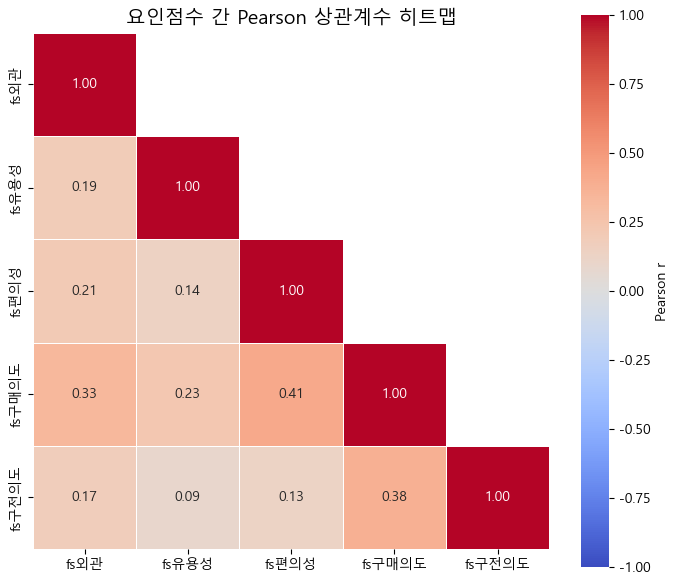

In [15]:
plt.figure(figsize=(7, 6))

# 대각선 위쪽은 가려서 중복 표시를 피한다.
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
    cbar_kws={'label': 'Pearson r'}
)
plt.title('요인점수 간 Pearson 상관계수 히트맵', fontsize=14)
plt.tight_layout()
plt.show()

### 4.5 산점도 행렬 (Pairplot)

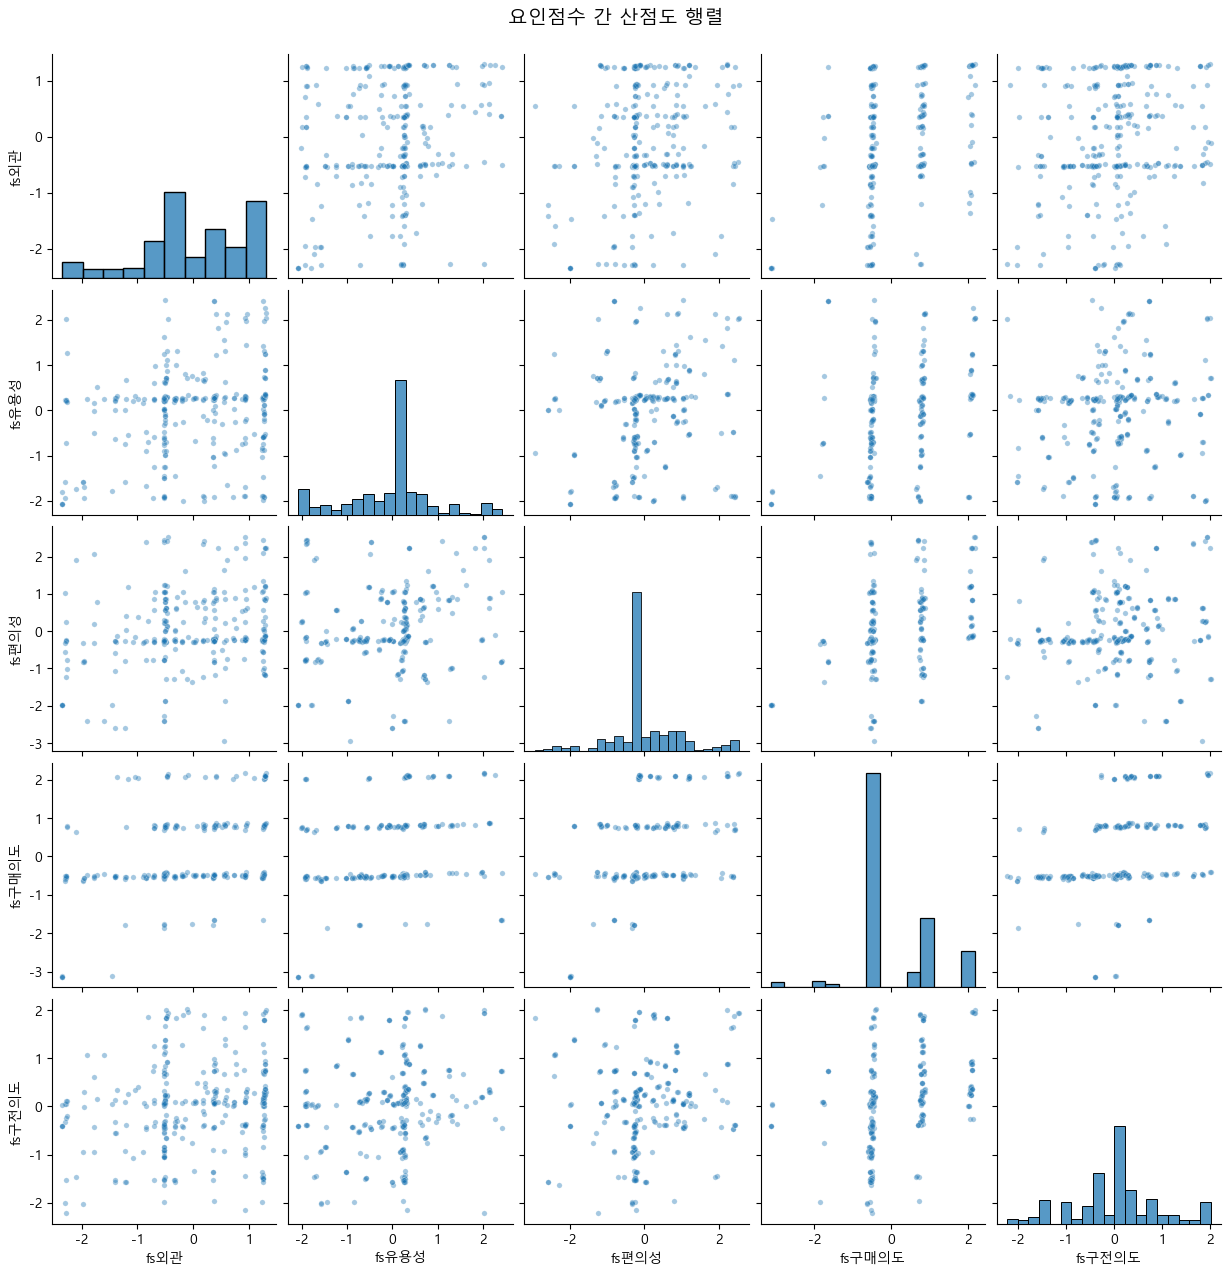

In [16]:
sns.pairplot(fs_data, diag_kind='hist', plot_kws={'alpha': 0.4, 's': 15})
plt.suptitle('요인점수 간 산점도 행렬', y=1.02, fontsize=14)
plt.show()

### 4.6 가장 강한 상관관계 정리

5개 요인 간 10개의 쌍 중, 상관의 크기가 큰 순서대로 정리하여 어떤 요인 쌍이 가장
밀접하게 연결되어 있는지 확인한다.

In [17]:
pairs = []
for i in range(n_vars):
    for j in range(i + 1, n_vars):
        pairs.append({
            '요인 1': columns[i],
            '요인 2': columns[j],
            'r': corr_matrix.iloc[i, j],
            'p-value': pvalue_matrix.iloc[i, j],
        })

pairs_df = pd.DataFrame(pairs).sort_values('r', ascending=False).reset_index(drop=True)
pairs_df.round(4)

,요인 1,요인 2,r,p-value
0,fs편의성,fs구매의도,0.4149,0.0000
1,fs구매의도,fs구전의도,0.3821,0.0000
2,fs외관,fs구매의도,0.3325,0.0000
3,fs유용성,fs구매의도,0.2326,0.0000
4,fs외관,fs편의성,0.2106,0.0001
5,fs외관,fs유용성,0.1929,0.0005
6,fs외관,fs구전의도,0.1729,0.0018
7,fs유용성,fs편의성,0.1397,0.0117
8,fs편의성,fs구전의도,0.1307,0.0184
9,fs유용성,fs구전의도,0.0900,0.1055


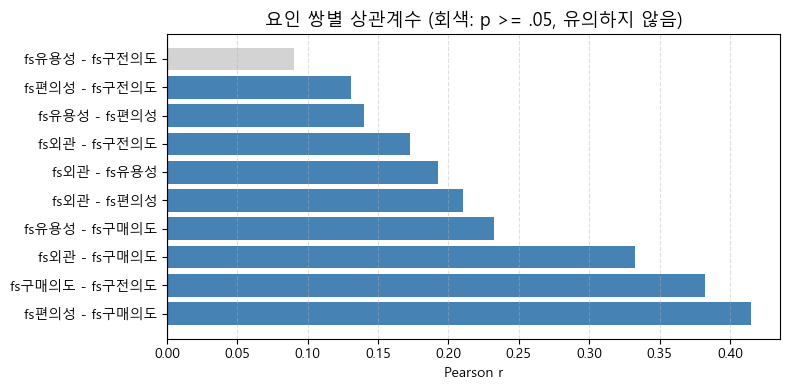

In [18]:
plt.figure(figsize=(8, 4))
colors = ['steelblue' if p < 0.05 else 'lightgray' for p in pairs_df['p-value']]
plt.barh(pairs_df['요인 1'] + ' - ' + pairs_df['요인 2'], pairs_df['r'], color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Pearson r')
plt.title('요인 쌍별 상관계수 (회색: p >= .05, 유의하지 않음)', fontsize=13)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 4.7 상관분석 결과 해석

- 10개의 요인 쌍 중 '유용성-구전의도'를 제외한 9개 쌍에서 통계적으로 유의한(p < .05)
  양의 상관관계가 확인된다. 즉 대부분의 요인들은 서로 독립적이지 않고, 한 요인에 대한
  인식이 높은 응답자는 다른 요인에 대해서도 대체로 높게 평가하는 경향이 있다.
- 상관의 크기를 기준으로 보면 **'편의성-구매의도'(r ≈ .41)**와 **'구매의도-구전의도'
  (r ≈ .38)**의 상관이 가장 강하게 나타난다. 이는 서비스 이용이 편리하다고 느낄수록
  재구매 의도가 높아지고, 재구매 의도가 높은 사람일수록 주변에 추천하려는 의도(구전의도)
  도 함께 높아지는 경향을 시사한다. 즉 '편의성 → 구매의도 → 구전의도'로 이어지는
  경로를 가정해 볼 수 있다.
- 반대로 **'유용성-구전의도'(r ≈ .09, p ≈ .106)**는 유의하지 않은 상관을 보인다. 서비스의
  유용성에 대한 인식이 반드시 타인에게 추천하려는 의도로 직접 이어지지는 않는다는 의미로
  해석할 수 있다. '유용성-편의성'(r ≈ .14) 역시 다른 쌍들에 비해 상대적으로 약한 상관을
  보인다.
- 모든 상관계수가 1에 비해 충분히 작다(가장 큰 값도 약 0.41)는 점은, 5개 요인이 서로
  겹치지 않는 별개의 개념으로 측정되고 있다는 근거이기도 하다. 만약 두 요인 간 상관이
  지나치게 높다면(예: 0.8 이상) 두 요인이 사실상 같은 개념을 중복 측정하고 있다고
  의심할 수 있는데, 본 데이터에서는 그런 패턴이 관찰되지 않는다.

## 5. 종합 결론

### 5.1 분석 요약

본 레포트는 설문조사 데이터를 신뢰도분석과 상관분석 두 단계로 분석했다.

1. **신뢰도분석**: 15개 문항을 5개 요인(외관, 유용성, 편의성, 구매의도, 구전의도)으로
   묶은 척도 설계가 통계적으로 타당한지 Cronbach's alpha로 검증했다. 5개 요인 모두
   alpha가 0.7 이상(외관 0.95, 유용성 0.76, 편의성 0.87, 구매의도 0.88, 구전의도 0.81)
   으로 나타나 신뢰도가 확보되었으며, 문항 제거 시 alpha 변화 및 수정된 문항-전체 상관
   분석에서도 제거를 고려할 만한 문제 문항은 발견되지 않았다.
2. **상관분석**: 신뢰도가 확인된 요인들로부터 산출된 요인점수 간 Pearson 상관관계를
   분석했다. '편의성-구매의도', '구매의도-구전의도' 쌍에서 비교적 강한 양의 상관이
   확인되었고, '유용성-구전의도' 쌍만 유의하지 않은 관계로 나타났다. 전반적으로 요인들은
   서로 양의 상관을 보이면서도, 상관의 크기가 지나치게 크지 않아 서로 구별되는 개념으로
   측정되고 있음을 확인했다.

### 5.2 분석의 의의와 한계

신뢰도분석을 먼저 수행하여 "문항들이 믿을 만한가"를 확인한 뒤, 그 문항들로부터 산출된
요인점수로 상관분석을 수행하는 순서는 설문 기반 연구의 표준적인 절차이다. 본 레포트는
이 순서를 그대로 따름으로써, 상관분석 결과(요인 간 관계)가 측정 도구의 신뢰성이라는
토대 위에서 해석될 수 있도록 했다.

다만 본 분석은 상관관계만을 다루고 있어 인과관계를 주장할 수는 없다. 예를 들어
'편의성이 높을수록 구매의도가 높다'는 관찰은 가능하지만, 편의성이 구매의도를 직접
'유발'하는지, 아니면 제3의 요인이 둘 다에 영향을 미치는지는 회귀분석이나 구조방정식
모형과 같은 추가적인 분석이 필요하다.